Este notebook fue hecho a manera de ensayo 

para armar e iterar sobre el algoritmo que extrae las ventanas sobre el pixel, calcular los indices, etc.

### La implmentacion final esta en tools/ac/extract_windows.py

In [1]:
import sys
from pathlib import Path

_REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
sys.path.insert(0, str(_REPO_ROOT))
from core.s3 import get_s3_client

import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd
import os
import glob
from PIL import Image
import matplotlib.pyplot as plt
from dotenv import load_dotenv
load_dotenv()

True

In [2]:
ACOLITE_SAVE_DIR = Path("../../data/acolite")
from core.s3 import DEFAULT_BUCKET

In [4]:
def is_lw2_downloaded(pass_id_save_path: Path):
    l2c_files = glob.glob(str(pass_id_save_path / "*L2W.nc"))
    return len(l2c_files) > 0

In [5]:
def download_pass_id_files(pass_id_prefix, s3):
    pass_id_paginator = s3.get_paginator("list_objects_v2")

    pass_id_iterator = pass_id_paginator.paginate(
        Bucket=DEFAULT_BUCKET,
        Prefix=f"{pass_id_prefix}/",
    )

    pass_id_save_path = ACOLITE_SAVE_DIR / pass_id_prefix.split("/")[1]

    if is_lw2_downloaded(pass_id_save_path):
        print(f"Skipping {pass_id_save_path}, already downloaded.")
        return False

    os.makedirs(pass_id_save_path, exist_ok=True)

    for file in pass_id_iterator:
        if not "Contents" in file:
            print(f"Folder : {pass_id_prefix} is empty")
            continue

        contents = file.get("Contents")

        for obj in contents:
            key = obj["Key"]
            if key.endswith("L2W.nc") or key.endswith(".png"):
                fname = key.split("/")[-1]
                s3.download_file(
                    Bucket=DEFAULT_BUCKET,
                    Key=key,
                    Filename=pass_id_save_path / fname
                )
    return True

In [6]:
s3 = get_s3_client()

In [7]:
download_pass_id_files("acolite/S2A_MSIL1C_20170104T135052_N0500_R024_T21HUC_20230920T013246", s3)

Skipping ../../data/acolite/S2A_MSIL1C_20170104T135052_N0500_R024_T21HUC_20230920T013246, already downloaded.


False

In [8]:
ACOLITE_DIR = Path("../../data/acolite")
acolite_pass_folders = glob.glob(f"{ACOLITE_DIR}/*")

In [9]:
def get_pass_files(pass_id: str):
    download_pass_id_files(f"acolite/{pass_id}", s3)
    files = glob.glob(f"{ACOLITE_DIR}/{pass_id}/*")
    imgs = []
    
    for f in files:
        print(f)
        if f.endswith(".png"):
            img = Image.open(f)
            imgs.append(img)
        else:
           product = xr.open_dataset(f) 
    return {
        "imgs" : imgs,
        "product": product
    }

In [10]:
pass_data = get_pass_files("S2A_MSIL1C_20170104T135052_N0500_R024_T21HUC_20230920T013246")
pass_data

Skipping ../../data/acolite/S2A_MSIL1C_20170104T135052_N0500_R024_T21HUC_20230920T013246, already downloaded.
../../data/acolite/S2A_MSIL1C_20170104T135052_N0500_R024_T21HUC_20230920T013246/S2A_MSI_2017_01_04_14_01_54_T21HUC_L2R_rgb_rhot.png
../../data/acolite/S2A_MSIL1C_20170104T135052_N0500_R024_T21HUC_20230920T013246/S2A_MSI_2017_01_04_14_01_54_T21HUC_L2W.nc
../../data/acolite/S2A_MSIL1C_20170104T135052_N0500_R024_T21HUC_20230920T013246/S2A_MSI_2017_01_04_14_01_54_T21HUC_L2R_rgb_rhos.png
../../data/acolite/S2A_MSIL1C_20170104T135052_N0500_R024_T21HUC_20230920T013246/S2A_MSI_2017_01_04_14_01_54_T21HUC_L1R_rgb_rhot.png


{'imgs': [<PIL.PngImagePlugin.PngImageFile image mode=RGBA size=1378x1296>,
  <PIL.PngImagePlugin.PngImageFile image mode=RGBA size=1378x1296>,
  <PIL.PngImagePlugin.PngImageFile image mode=RGBA size=1378x1296>],
 'product': <xarray.Dataset> Size: 87MB
 Dimensions:              (y: 1146, x: 1363)
 Coordinates:
   * y                    (y) float64 9kB 6.225e+06 6.225e+06 ... 6.202e+06
   * x                    (x) float64 11kB 3.826e+05 3.826e+05 ... 4.098e+05
 Data variables: (12/15)
     transverse_mercator  float64 8B ...
     lon                  (y, x) float32 6MB ...
     lat                  (y, x) float32 6MB ...
     rhow_443             (y, x) float32 6MB ...
     rhow_492             (y, x) float32 6MB ...
     rhow_560             (y, x) float32 6MB ...
     ...                   ...
     rhow_783             (y, x) float32 6MB ...
     rhow_833             (y, x) float32 6MB ...
     rhow_865             (y, x) float32 6MB ...
     rhow_1614            (y, x) float32 6MB .

In [11]:
def show_rgbs(imgs):
    cmaps  = [None, None, None]
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    
    for ax, img, cmap in zip(axes, imgs, cmaps):
        im = ax.imshow(img, cmap=cmap)
        ax.axis("off")
    
    fig.suptitle("RGb de pass")
    plt.tight_layout()
    plt.show()

#### Extrayendo Ventanas en puntos
*Para cada escena:*

1. Get pass id de la escena
2. filtrar los puntos de esa escena
3. 

In [12]:
PASS_ID = "S2A_MSIL1C_20170305T140151_N0500_R024_T21HUC_20230909T044812"

In [13]:
pass_data_2 = get_pass_files(PASS_ID)
pass_data_2

Skipping ../../data/acolite/S2A_MSIL1C_20170305T140151_N0500_R024_T21HUC_20230909T044812, already downloaded.
../../data/acolite/S2A_MSIL1C_20170305T140151_N0500_R024_T21HUC_20230909T044812/S2A_MSI_2017_03_05_14_01_58_T21HUC_L2R_rgb_rhot.png
../../data/acolite/S2A_MSIL1C_20170305T140151_N0500_R024_T21HUC_20230909T044812/S2A_MSI_2017_03_05_14_01_58_T21HUC_L2W.nc
../../data/acolite/S2A_MSIL1C_20170305T140151_N0500_R024_T21HUC_20230909T044812/S2A_MSI_2017_03_05_14_01_58_T21HUC_L2R_rgb_rhos.png
../../data/acolite/S2A_MSIL1C_20170305T140151_N0500_R024_T21HUC_20230909T044812/S2A_MSI_2017_03_05_14_01_58_T21HUC_L1R_rgb_rhot.png


{'imgs': [<PIL.PngImagePlugin.PngImageFile image mode=RGBA size=1378x1296>,
  <PIL.PngImagePlugin.PngImageFile image mode=RGBA size=1378x1296>,
  <PIL.PngImagePlugin.PngImageFile image mode=RGBA size=1378x1296>],
 'product': <xarray.Dataset> Size: 87MB
 Dimensions:              (y: 1146, x: 1363)
 Coordinates:
   * y                    (y) float64 9kB 6.225e+06 6.225e+06 ... 6.202e+06
   * x                    (x) float64 11kB 3.826e+05 3.826e+05 ... 4.098e+05
 Data variables: (12/15)
     transverse_mercator  float64 8B ...
     lon                  (y, x) float32 6MB ...
     lat                  (y, x) float32 6MB ...
     rhow_443             (y, x) float32 6MB ...
     rhow_492             (y, x) float32 6MB ...
     rhow_560             (y, x) float32 6MB ...
     ...                   ...
     rhow_783             (y, x) float32 6MB ...
     rhow_833             (y, x) float32 6MB ...
     rhow_865             (y, x) float32 6MB ...
     rhow_1614            (y, x) float32 6MB .

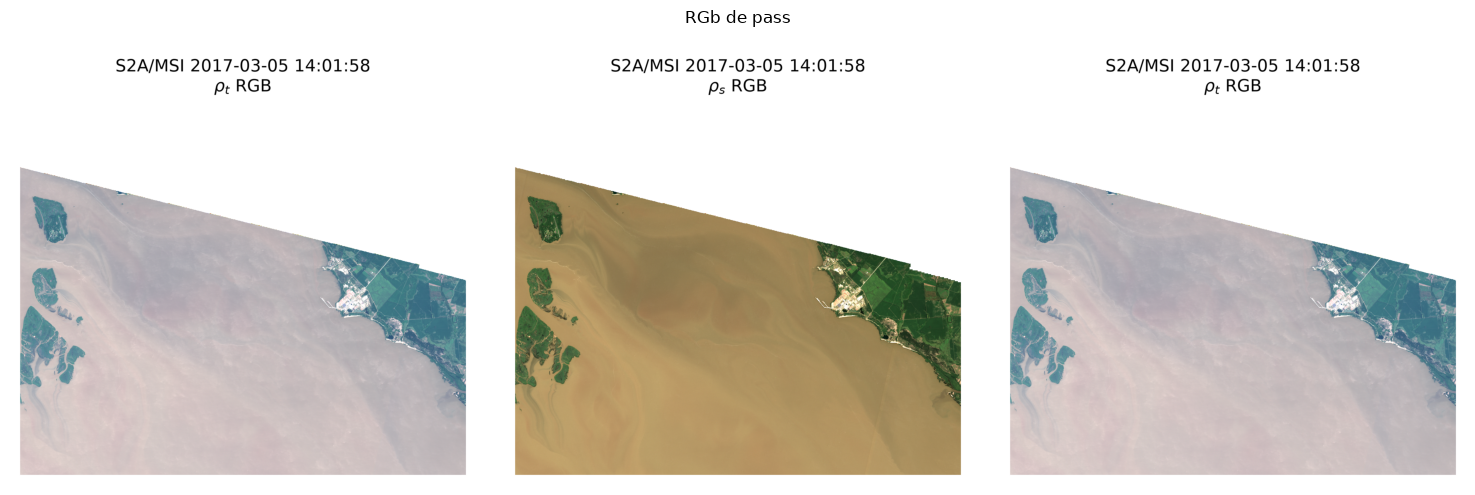

In [14]:
show_rgbs(pass_data_2["imgs"])

In [15]:
dl = pass_data_2["product"]
new_band_names = {
    "rhow_443":  "B01", # no
    "rhow_492":  "B02",
    "rhow_560":  "B03",
    "rhow_665":  "B04",
    "rhow_704":  "B05",
    "rhow_740":  "B06",
    "rhow_783":  "B07",
    "rhow_833":  "B08", # no
    "rhow_865":  "B8A", # no
    "rhow_1614": "B11", # no
    "rhow_2202": "B12", # no
}
dl = dl.rename(new_band_names)
dl

<xarray.Dataset> Size: 87MB
Dimensions:              (y: 1146, x: 1363)
Coordinates:
  * y                    (y) float64 9kB 6.225e+06 6.225e+06 ... 6.202e+06
  * x                    (x) float64 11kB 3.826e+05 3.826e+05 ... 4.098e+05
Data variables: (12/15)
    transverse_mercator  float64 8B ...
    lon                  (y, x) float32 6MB ...
    lat                  (y, x) float32 6MB ...
    B01                  (y, x) float32 6MB ...
    B02                  (y, x) float32 6MB ...
    B03                  (y, x) float32 6MB ...
    ...                   ...
    B07                  (y, x) float32 6MB ...
    B08                  (y, x) float32 6MB ...
    B8A                  (y, x) float32 6MB ...
    B11                  (y, x) float32 6MB ...
    B12                  (y, x) float32 6MB ...
    l2_flags             (y, x) int32 6MB ...
Attributes: (12/507)
    generated_by:                                         ACOLITE
    generated_on:                                         2026-10-07 02:47:19...
    contact:                                              Quinten Vanhellemont
    acolite_version:                                      GitHub Clone
    product_type:                                         NetCDF
    metadata_profile:                                     beam
    ...                                                   ...
    8_rhod:                                               0.007623717160888737
    8A_rhod:                                              0.019815720594044323
    ac_band1_idx:                                         7
    ac_band1:                                             8
    ac_band2_idx:                                         0
    ac_band2:                                             1

In [16]:
dl["l2_flags"].values

array([[16, 16, 16, ..., 21, 21, 21],
       [16, 16, 16, ..., 21, 21, 21],
       [16, 16, 16, ..., 21, 21, 21],
       ...,
       [ 0,  0,  0, ...,  0,  0,  0],
       [ 0,  0,  0, ...,  0,  0,  0],
       [ 0,  0,  0, ...,  0,  0,  0]], shape=(1146, 1363), dtype=int32)

In [17]:
PIXEL_BUENO = 0
NO_AGUA = 1                 # supera l2w_mask_threshold en el infrarrojo (1600 nm)
CIRRUS = 2                  # nubes altas y finas
MUY_BRILLANTE = 4           # reflectancia muy alta arriba de la atmósfera (nubes, reflejos)
REFLECTANCIA_NEGATIVA = 8   # algún valor negativo entre 400 y 900 nm
FUERA_DE_ESCENA = 16        # fuera de la imagen
MIXTO = 32                  # píxel mezclado
SOMBRA_RELIEVE = 64         # sombra por montañas (solo si lo activaste)

In [18]:
matchups = gpd.read_file("../../data/nuevos/matchups_registros_finales.geojson")

In [19]:
matchups.head()

,fecha,fuente,chla,grupo_nombre,estado_trofico,pass_id,delta,geometry
0,2017-01-02,OAN,8.9,RDP-MONTES,M,S2A_MSIL1C_20170104T135052_N0500_R024_T21HUC_2...,222652.026,POINT (401164.986 6214585.025)
1,2017-01-02,GEMS,6.8,LDS,O,S2A_MSIL1C_20161229T133222_N0500_R081_T21HXB_2...,296857.974,POINT (678380.002 6147956.963)
2,2017-01-02,GEMS,3.2,LDS,O,S2A_MSIL1C_20161229T133222_N0500_R081_T21HXB_2...,296857.974,POINT (679045.962 6144090.994)
3,2017-01-02,OAN,4.4,RDP-MONTES,O,S2A_MSIL1C_20170104T135052_N0500_R024_T21HUC_2...,222652.026,POINT (402233.023 6210401.038)
4,2017-01-02,OAN,5.9,RDP-MONTES,O,S2A_MSIL1C_20170104T135052_N0500_R024_T21HUC_2...,222652.026,POINT (401555.004 6213022.975)


In [20]:
matchups = matchups.to_crs("EPSG:4326") 

In [21]:
matchups.head()

,fecha,fuente,chla,grupo_nombre,estado_trofico,pass_id,delta,geometry
0,2017-01-02,OAN,8.9,RDP-MONTES,M,S2A_MSIL1C_20170104T135052_N0500_R024_T21HUC_2...,222652.026,POINT (-58.07281 -34.20508)
1,2017-01-02,GEMS,6.8,LDS,O,S2A_MSIL1C_20161229T133222_N0500_R081_T21HXB_2...,296857.974,POINT (-55.05017 -34.79501)
2,2017-01-02,GEMS,3.2,LDS,O,S2A_MSIL1C_20161229T133222_N0500_R081_T21HXB_2...,296857.974,POINT (-55.04207 -34.82973)
3,2017-01-02,OAN,4.4,RDP-MONTES,O,S2A_MSIL1C_20170104T135052_N0500_R024_T21HUC_2...,222652.026,POINT (-58.06169 -34.2429)
4,2017-01-02,OAN,5.9,RDP-MONTES,O,S2A_MSIL1C_20170104T135052_N0500_R024_T21HUC_2...,222652.026,POINT (-58.06875 -34.2192)


In [22]:
matchups["lon"] = matchups.geometry.x
matchups["lat"] = matchups.geometry.y

In [25]:
puntos_i = matchups.drop(columns="geometry")
puntos = pd.DataFrame(puntos_i)
puntos.head()

,fecha,fuente,chla,grupo_nombre,estado_trofico,pass_id,delta,lon,lat
0,2017-01-02,OAN,8.9,RDP-MONTES,M,S2A_MSIL1C_20170104T135052_N0500_R024_T21HUC_2...,222652.026,-58.072809,-34.205076
1,2017-01-02,GEMS,6.8,LDS,O,S2A_MSIL1C_20161229T133222_N0500_R081_T21HXB_2...,296857.974,-55.050169,-34.795008
2,2017-01-02,GEMS,3.2,LDS,O,S2A_MSIL1C_20161229T133222_N0500_R081_T21HXB_2...,296857.974,-55.042069,-34.829733
3,2017-01-02,OAN,4.4,RDP-MONTES,O,S2A_MSIL1C_20170104T135052_N0500_R024_T21HUC_2...,222652.026,-58.061691,-34.242904
4,2017-01-02,OAN,5.9,RDP-MONTES,O,S2A_MSIL1C_20170104T135052_N0500_R024_T21HUC_2...,222652.026,-58.068754,-34.219198


In [26]:
puntos["delta"] = pd.to_timedelta(puntos["delta"], unit="s").dt.round("s")

In [27]:
puntos.head()

,fecha,fuente,chla,grupo_nombre,estado_trofico,pass_id,delta,lon,lat
0,2017-01-02,OAN,8.9,RDP-MONTES,M,S2A_MSIL1C_20170104T135052_N0500_R024_T21HUC_2...,2 days 13:50:52,-58.072809,-34.205076
1,2017-01-02,GEMS,6.8,LDS,O,S2A_MSIL1C_20161229T133222_N0500_R081_T21HXB_2...,3 days 10:27:38,-55.050169,-34.795008
2,2017-01-02,GEMS,3.2,LDS,O,S2A_MSIL1C_20161229T133222_N0500_R081_T21HXB_2...,3 days 10:27:38,-55.042069,-34.829733
3,2017-01-02,OAN,4.4,RDP-MONTES,O,S2A_MSIL1C_20170104T135052_N0500_R024_T21HUC_2...,2 days 13:50:52,-58.061691,-34.242904
4,2017-01-02,OAN,5.9,RDP-MONTES,O,S2A_MSIL1C_20170104T135052_N0500_R024_T21HUC_2...,2 days 13:50:52,-58.068754,-34.219198


In [28]:
puntos

,fecha,fuente,chla,grupo_nombre,estado_trofico,pass_id,delta,lon,lat
0,2017-01-02 00:00:00,OAN,8.9,RDP-MONTES,M,S2A_MSIL1C_20170104T135052_N0500_R024_T21HUC_2...,2 days 13:50:52,-58.072809,-34.205076
1,2017-01-02 00:00:00,GEMS,6.8,LDS,O,S2A_MSIL1C_20161229T133222_N0500_R081_T21HXB_2...,3 days 10:27:38,-55.050169,-34.795008
2,2017-01-02 00:00:00,GEMS,3.2,LDS,O,S2A_MSIL1C_20161229T133222_N0500_R081_T21HXB_2...,3 days 10:27:38,-55.042069,-34.829733
3,2017-01-02 00:00:00,OAN,4.4,RDP-MONTES,O,S2A_MSIL1C_20170104T135052_N0500_R024_T21HUC_2...,2 days 13:50:52,-58.061691,-34.242904
4,2017-01-02 00:00:00,OAN,5.9,RDP-MONTES,O,S2A_MSIL1C_20170104T135052_N0500_R024_T21HUC_2...,2 days 13:50:52,-58.068754,-34.219198
...,...,...,...,...,...,...,...,...,...
2958,2026-05-06 15:14:00,OAN,1.5,RN-UPM2,U,S2A_MSIL1C_20260506T134221_N0512_R124_T21HWD_2...,0 days 01:31:39,-56.568167,-32.843667
2959,2026-05-06 15:28:00,OAN,3.0,RN-UPM2,O,S2A_MSIL1C_20260506T134221_N0512_R124_T21HWD_2...,0 days 01:45:39,-56.567917,-32.842306
2960,2026-05-06 15:50:00,OAN,1.5,RN-UPM2,U,S2A_MSIL1C_20260506T134221_N0512_R124_T21HWD_2...,0 days 02:07:39,-56.566861,-32.840917
2961,2026-05-06 16:05:00,OAN,1.5,RN-UPM2,U,S2A_MSIL1C_20260506T134221_N0512_R124_T21HWD_2...,0 days 02:22:39,-56.561056,-32.844139


#### Puntos de esta escena para extraer ventantas

In [29]:
puntos.shape # 

(2963, 9)

In [30]:
mask = puntos["pass_id"] == PASS_ID 

In [31]:
puntos_escena = puntos[mask]
puntos_escena

,fecha,fuente,chla,grupo_nombre,estado_trofico,pass_id,delta,lon,lat
92,2017-03-06,OAN,5.9,RDP-MONTES,O,S2A_MSIL1C_20170305T140151_N0500_R024_T21HUC_2...,0 days 09:58:09,-58.068754,-34.219198
94,2017-03-06,OAN,5.9,RDP-MONTES,O,S2A_MSIL1C_20170305T140151_N0500_R024_T21HUC_2...,0 days 09:58:09,-58.169061,-34.168044
95,2017-03-06,OAN,5.9,RDP-MONTES,O,S2A_MSIL1C_20170305T140151_N0500_R024_T21HUC_2...,0 days 09:58:09,-58.223401,-34.164809
96,2017-03-06,OAN,20.7,RDP-MONTES,M,S2A_MSIL1C_20170305T140151_N0500_R024_T21HUC_2...,0 days 09:58:09,-58.072809,-34.205076
97,2017-03-06,OAN,1.5,RDP-MONTES,U,S2A_MSIL1C_20170305T140151_N0500_R024_T21HUC_2...,0 days 09:58:09,-58.061691,-34.242904
98,2017-03-06,OAN,5.9,RDP-MONTES,O,S2A_MSIL1C_20170305T140151_N0500_R024_T21HUC_2...,0 days 09:58:09,-57.995526,-34.268566
99,2017-03-06,OAN,3.0,RDP-MONTES,O,S2A_MSIL1C_20170305T140151_N0500_R024_T21HUC_2...,0 days 09:58:09,-58.057434,-34.243699


### Cantidad de pixels minimos para considera la ventana

In [32]:
MIN_PIXELS_VALIDOS = 5

#### Separamos las variables, pq en Xarray esta todo en una misma estructura

In [33]:
lat, lon = dl["lat"].values, dl["lon"].values
#
band_names = [v for v in dl.data_vars if v not in ("lat", "lon", "x", "y", "transverse_mercator", "l2_flags","B01","B08","B8A","B09","B10","B11","B12")]

flags = dl["l2_flags"]

In [34]:
# dimensions de la imagen
num_rows, num_cols = lat.shape

In [35]:
def dist_punto_pixeles(p, lat_pixels, lon_pixels): 
    # aproximación equirectangular
    d2 = (lat_pixels - p["lat"]) ** 2 + ((lon_pixels - p["lon"]) * np.cos(np.radians(p["lat"]))) ** 2 
    return d2
    

### Parte Principal

In [36]:
half = 2

In [38]:
nmro_p = 1
for idx, p in puntos_escena.iterrows():
    print(f"Punto {nmro_p}\n")
    # calculamos la distancia a cada pixel de p.
    d2 = dist_punto_pixeles(p, lat, lon)
    
    #  pixel con la distancia minima a p
    i, j = np.unravel_index(np.argmin(d2), d2.shape)

    # pasamos a metros
    dist_m = float(np.sqrt(d2[i, j]) * 111_320)

    # el slice es la ventana al rededor del punto (i, j)
    sl = (slice(max(i - half, 0), min(i + half + 1, num_rows)),
          slice(max(j - half, 0), min(j + half + 1, num_cols)))

    mask = flags.values[sl] == PIXEL_BUENO
    buenos = mask.sum()
    
    if buenos < MIN_PIXELS_VALIDOS:
        print("No hay pixeles suficientes")
        continue
    else: 
        
        # stats de cada banda
        
        for banda in band_names:
            ventana = dl[banda].values[sl]
            ventana = ventana[mask]
            
            q25, q75 = np.percentile(ventana, [25, 75]) # 
            media = float(np.mean(ventana))
            mediana = float(np.median(ventana))
            iqr = float(q75 - q25)
            std = float(np.std(ventana))

            cols = [f"{banda}_mean", f"{banda}_median", f"{banda}_iqr", f"{banda}_std"]
            puntos.loc[idx, cols] = [media, mediana, iqr, std]
            
        # indices

        B02 = dl["B02"].values[sl][mask]
        B03 = dl["B03"].values[sl][mask]
        B04 = dl["B04"].values[sl][mask]
        B05 = dl["B05"].values[sl][mask]
        B06 = dl["B06"].values[sl][mask]
        B07 = dl["B07"].values[sl][mask]
        
        L4, L5, L6 = 665, 705, 740
        ndci = (B05 - B04) / (B05 + B04) 
        tres_bandas = B07 * (0.1 * B04 - 0.1 * B05)
        combinado = B05 * (B06 + B04) / B02
        green_rededge = B03 / B06
        green_red = B03 / B04
        MCI = B05 - (B04 + (B06 - B04) * ((L5 - L4) / (L6 - L4)))

        
        indices = {
            "ndci": ndci,
            "tres_bandas": tres_bandas,
            "combinado": combinado,
            "green_rededge":  green_rededge,
            "green_red": green_red,
            "mci": MCI
        }

        for nombre, valores in indices.items():
            q25, q75 = np.percentile(valores, [25, 75])
            media = float(np.mean(valores))
            mediana = float(np.median(valores))
            iqr = float(q75 - q25)
            std = float(np.std(valores))

            cols = [f"{nombre}_mean", f"{nombre}_median", f"{nombre}_iqr", f"{nombre}_std"]
            puntos.loc[idx, cols] = [media, mediana, iqr, std]


    nmro_p += 1


Punto 1

Punto 2

No hay pixeles suficientes
Punto 2

Punto 3

Punto 4

Punto 5

Punto 6



In [39]:
puntos.loc[[idx]]

,fecha,fuente,chla,grupo_nombre,estado_trofico,pass_id,delta,lon,lat,B02_mean,...,green_rededge_iqr,green_rededge_std,green_red_mean,green_red_median,green_red_iqr,green_red_std,mci_mean,mci_median,mci_iqr,mci_std
99,2017-03-06,OAN,3.0,RDP-MONTES,O,S2A_MSIL1C_20170305T140151_N0500_R024_T21HUC_2...,0 days 09:58:09,-58.057434,-34.243699,0.049738,...,0.040974,0.039037,0.860905,0.85887,0.0192,0.013232,0.020779,0.020813,0.000463,0.000803


In [40]:
puntos[puntos["pass_id"] == PASS_ID]

,fecha,fuente,chla,grupo_nombre,estado_trofico,pass_id,delta,lon,lat,B02_mean,...,green_rededge_iqr,green_rededge_std,green_red_mean,green_red_median,green_red_iqr,green_red_std,mci_mean,mci_median,mci_iqr,mci_std
92,2017-03-06,OAN,5.9,RDP-MONTES,O,S2A_MSIL1C_20170305T140151_N0500_R024_T21HUC_2...,0 days 09:58:09,-58.068754,-34.219198,0.049907,...,0.063903,0.042409,0.858412,0.860184,0.012800,0.011240,0.022035,0.022117,0.001214,0.000887
94,2017-03-06,OAN,5.9,RDP-MONTES,O,S2A_MSIL1C_20170305T140151_N0500_R024_T21HUC_2...,0 days 09:58:09,-58.169061,-34.168044,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
95,2017-03-06,OAN,5.9,RDP-MONTES,O,S2A_MSIL1C_20170305T140151_N0500_R024_T21HUC_2...,0 days 09:58:09,-58.223401,-34.164809,0.045162,...,0.026323,0.056140,0.855000,0.853717,0.013291,0.013108,0.019421,0.019509,0.001162,0.000773
96,2017-03-06,OAN,20.7,RDP-MONTES,M,S2A_MSIL1C_20170305T140151_N0500_R024_T21HUC_2...,0 days 09:58:09,-58.072809,-34.205076,0.042480,...,0.067626,0.061560,0.880101,0.883420,0.021389,0.015157,0.018560,0.018325,0.001811,0.001385
97,2017-03-06,OAN,1.5,RDP-MONTES,U,S2A_MSIL1C_20170305T140151_N0500_R024_T21HUC_2...,0 days 09:58:09,-58.061691,-34.242904,0.049496,...,0.070027,0.063902,0.865903,0.865225,0.019640,0.012356,0.020681,0.020589,0.001163,0.000744
98,2017-03-06,OAN,5.9,RDP-MONTES,O,S2A_MSIL1C_20170305T140151_N0500_R024_T21HUC_2...,0 days 09:58:09,-57.995526,-34.268566,0.043415,...,0.105422,0.393745,0.906753,0.886707,0.019643,0.100154,0.017499,0.019506,0.001617,0.005275
99,2017-03-06,OAN,3.0,RDP-MONTES,O,S2A_MSIL1C_20170305T140151_N0500_R024_T21HUC_2...,0 days 09:58:09,-58.057434,-34.243699,0.049738,...,0.040974,0.039037,0.860905,0.858870,0.019200,0.013232,0.020779,0.020813,0.000463,0.000803
